# Dana's Bakery: deterministic LangGraph orders
Run all cells in a fresh Google Colab Python runtime. No model, API key, or AI service is used.

## State and routing
`OrderInput` contains item, quantity, day, and city. `OrderState` adds a fresh stock snapshot,
original item, substitution attempts, route, monetary amounts, and an ordered `steps` trace.
`OrderOutput` exposes exactly status, item, delivery, total, message, and steps.
Prices are calculated with `Decimal` and returned as NIS numbers with two-decimal precision.

Validation normalizes text and rejects unknown/discontinued products and non-positive-integer quantities
(including booleans, floats, and numeric strings). Stock checking accepts only full quantities.
Substitution advances one product at a time, retaining quantity, with at most two attempts and no wrap.
Discount routes to either apply or skip; delivery routes to Jerusalem delivery, pickup, or converted pickup.
All rejection routes converge on the final template response with no sold item and total zero.

```mermaid
flowchart TD
  START --> validate
  validate -->|valid| check_stock
  validate -->|invalid| final_response
  check_stock -->|available| discount
  check_stock -->|insufficient, attempts left| substitute
  substitute --> check_stock
  check_stock -->|exhausted| final_response
  discount -->|eligible| apply_discount
  discount -->|otherwise| skip_discount
  apply_discount --> delivery
  skip_discount --> delivery
  delivery -->|Jerusalem| jerusalem_delivery
  delivery -->|empty| pickup
  delivery -->|elsewhere| outside_pickup
  jerusalem_delivery --> final_response
  pickup --> final_response
  outside_pickup --> final_response
  final_response --> END
```

Assumptions: text is stripped and case-insensitive; non-Friday day strings are eligible weekdays
for the discount rule. Day and city must be strings. Rejected delivery is `none`.
Stock is a per-order snapshot, not a persistent inventory service.

In [1]:
%pip install -q langgraph==1.0.3 langchain-core==1.6.10 "ipython>=7" pyppeteer==2.0.0 nest_asyncio==1.6.0



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from decimal import Decimal
from typing import Any
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END

class OrderInput(TypedDict):
    item: str
    quantity: int
    day: str
    city: str

class OrderOutput(TypedDict):
    status: str
    item: str | None
    delivery: str
    total: float
    message: str
    steps: list[str]

class OrderState(TypedDict, total=False):
    item: Any
    quantity: Any
    day: Any
    city: Any
    original_item: str
    stock: dict[str, int]
    attempts: int
    route: str
    reason: str
    subtotal: Decimal
    merchandise: Decimal
    discounted: bool
    fee: Decimal
    status: str
    delivery: str
    total: float
    message: str
    steps: list[str]

PRICES = {"challah": Decimal("18"), "babka": Decimal("45"),
          "rugelach": Decimal("30"), "sourdough": Decimal("25")}
SEQUENCE = ("babka", "rugelach", "sourdough", "challah")

def fresh_stock():
    # Never share mutable inventory between invocations.
    return {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}

def visit(state, name, **updates):
    return {"steps": [*state.get("steps", []), name], **updates}

def validate(state):
    item = state.get("item")
    item = item.strip().lower() if isinstance(item, str) else ""
    quantity = state.get("quantity")
    reason = ""
    if item in {"croissant", "croissants"}:
        reason = "Croissants are discontinued. Please choose another bakery treat."
    elif item not in PRICES:
        reason = "Please choose challah, babka, rugelach, or sourdough."
    elif type(quantity) is not int or quantity <= 0:
        reason = "Please enter a quantity that is a positive integer."
    elif not all(isinstance(state.get(k), str) for k in ("day", "city")):
        reason = "Please provide day and city as text; use an empty city for pickup."
    return {"steps": ["validate"], "item": item, "original_item": item,
            "stock": fresh_stock(), "attempts": 0, "reason": reason,
            "route": "reject" if reason else "stock",
            "day": str(state.get("day", "")).strip().lower(),
            "city": str(state.get("city", "")).strip()}

def check_stock(state):
    item, quantity = state["item"], state["quantity"]
    if state["stock"][item] >= quantity:
        subtotal = PRICES[item] * quantity
        return visit(state, f"check_stock:{item}", route="price", subtotal=subtotal)
    has_next = SEQUENCE.index(item) < len(SEQUENCE) - 1
    if state["attempts"] < 2 and has_next:
        return visit(state, f"check_stock:{item}", route="substitute")
    return visit(state, f"check_stock:{item}", route="reject",
                 reason=f"We cannot fill all {quantity} of your requested {state['original_item']} "
                        "with the available stock and permitted substitutions. Please try a smaller order.")

def substitute(state):
    next_item = SEQUENCE[SEQUENCE.index(state["item"]) + 1]
    return visit(state, f"substitute:{state['item']}->{next_item}",
                 item=next_item, attempts=state["attempts"] + 1)

def discount(state):
    eligible = state["subtotal"] > Decimal("150") and state["day"] != "friday"
    return visit(state, "discount", route="apply" if eligible else "skip")

def apply_discount(state):
    return visit(state, "apply_discount", discounted=True,
                 merchandise=(state["subtotal"] * Decimal("0.85")).quantize(Decimal("0.01")))

def skip_discount(state):
    return visit(state, "skip_discount", discounted=False, merchandise=state["subtotal"])

def delivery(state):
    city = state["city"].lower()
    return visit(state, "delivery", route="jerusalem" if city == "jerusalem" else
                 "pickup" if not city else "outside")

def jerusalem_delivery(state):
    return visit(state, "jerusalem_delivery", delivery="delivery", fee=Decimal("20"))

def pickup(state):
    return visit(state, "pickup", delivery="pickup", fee=Decimal("0"))

def outside_pickup(state):
    return visit(state, "outside_pickup", delivery="pickup", fee=Decimal("0"))

def final_response(state):
    if state["reason"]:
        return visit(state, "final_response", status="rejected", item=None,
                     delivery="none", total=0.0,
                     message=f"Thank you for choosing Dana's Bakery! {state['reason']} We'd love to help next time.")
    parts = ["Thank you for choosing Dana's Bakery!"]
    if state["attempts"]:
        parts.append(f"We substituted {state['item']} for {state['original_item']} "
                     f"and kept your quantity of {state['quantity']}.")
    parts.append(f"Your order of {state['quantity']} {state['item']} is confirmed.")
    if state["discounted"]:
        parts.append("Your merchandise received a 15% discount.")
    if state["delivery"] == "delivery":
        parts.append("Delivery to Jerusalem costs 20.00 NIS.")
    elif state["city"]:
        parts.append(f"We deliver only within Jerusalem, so delivery to {state['city']} "
                     "has been changed to free pickup.")
    else:
        parts.append("Free pickup is arranged for you.")
    total = state["merchandise"] + state["fee"]
    parts.append(f"Your total is {total:.2f} NIS. Enjoy your treats!")
    return visit(state, "final_response", status="confirmed", total=float(total), message=" ".join(parts))

builder = StateGraph(OrderState, input_schema=OrderInput, output_schema=OrderOutput)
for node in (validate, check_stock, substitute, discount, apply_discount, skip_discount,
             delivery, jerusalem_delivery, pickup, outside_pickup, final_response):
    builder.add_node(node.__name__, node)
builder.add_edge(START, "validate")
builder.add_conditional_edges("validate", lambda s: s["route"],
                              {"reject": "final_response", "stock": "check_stock"})
builder.add_conditional_edges("check_stock", lambda s: s["route"],
                              {"price": "discount", "substitute": "substitute", "reject": "final_response"})
builder.add_edge("substitute", "check_stock")
builder.add_conditional_edges("discount", lambda s: s["route"],
                              {"apply": "apply_discount", "skip": "skip_discount"})
for node in ("apply_discount", "skip_discount"):
    builder.add_edge(node, "delivery")
builder.add_conditional_edges("delivery", lambda s: s["route"],
                              {"jerusalem": "jerusalem_delivery", "pickup": "pickup", "outside": "outside_pickup"})
for node in ("jerusalem_delivery", "pickup", "outside_pickup"):
    builder.add_edge(node, "final_response")
builder.add_edge("final_response", END)
graph = builder.compile()

/tmp/bakery-venv/lib/python3.12/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


## Actual compiled graph
The following cell renders the compiled graph with `draw_mermaid_png()` and displays its PNG.
It uses local Chromium through Pyppeteer, avoiding a remote rendering service.
The first run downloads Chromium if no installed browser is found; package/browser downloads
and the Mermaid JavaScript CDN require internet access. No customer order is sent to an AI service.

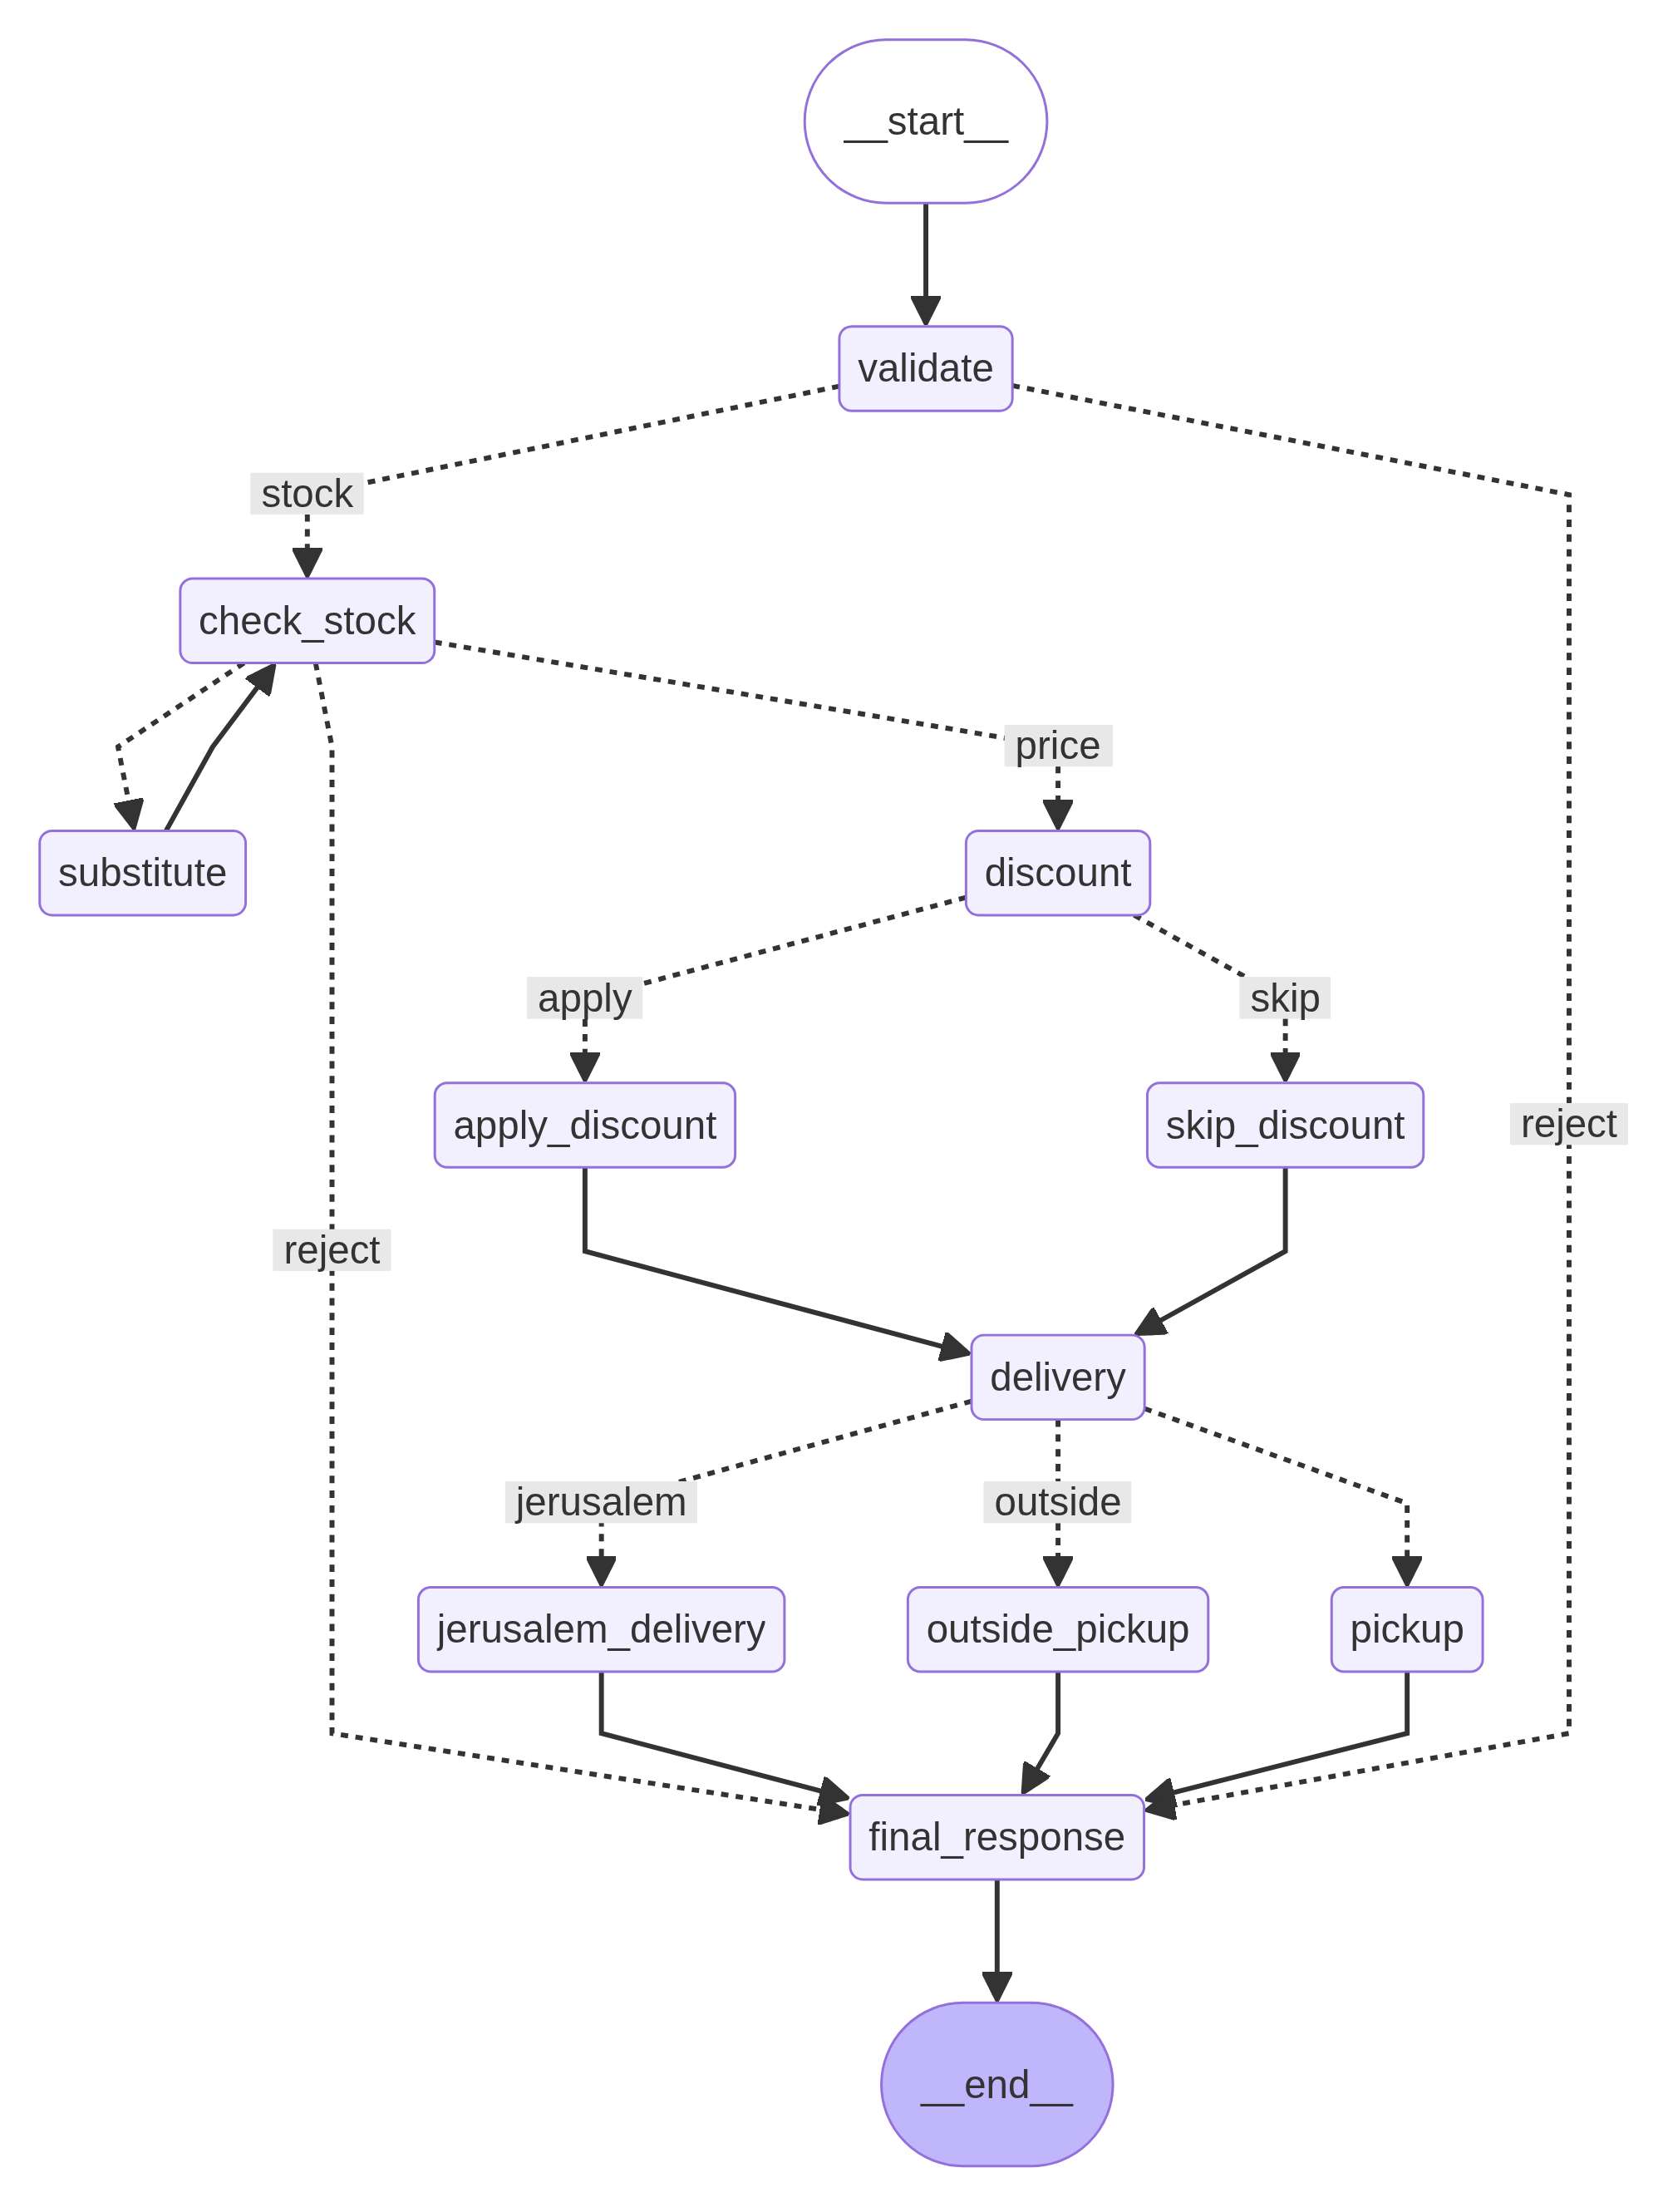

In [3]:
import os
import shutil
from IPython.display import Image, display
from langchain_core.runnables.graph import MermaidDrawMethod

# Colab may already have Chromium; otherwise Pyppeteer downloads its bundled browser.
chromium = shutil.which("chromium") or shutil.which("chromium-browser") or shutil.which("google-chrome")
if chromium:
    os.environ["PYPPETEER_EXECUTABLE_PATH"] = chromium
# LangChain's synchronous renderer uses run_until_complete; Colab already has an event loop.
import nest_asyncio
nest_asyncio.apply()
# Colab runs as root, so its browser needs these sandbox flags.
from tempfile import TemporaryDirectory
from functools import partial
from unittest.mock import patch
from pyppeteer import launch
from pyppeteer.page import Page
from urllib.request import urlopen

# Fetch a fixed Mermaid release through Python's TLS/proxy configuration, then
# load it locally in Chromium. This also works behind managed notebook proxies.
with urlopen("https://cdn.jsdelivr.net/npm/mermaid@10.9.3/dist/mermaid.min.js", timeout=60) as response:
    mermaid_js = response.read().decode("utf-8")
original_add_script = Page.addScriptTag

async def add_local_mermaid(page, options, **kwargs):
    if "url" in options and "mermaid" in options["url"]:
        return await original_add_script(page, {"content": mermaid_js})
    return await original_add_script(page, options, **kwargs)

browser_options = {"args": ["--no-sandbox", "--disable-setuid-sandbox"]}
if chromium:
    browser_options["executablePath"] = chromium
with TemporaryDirectory(prefix="bakery-browser-") as profile:
    browser_options["userDataDir"] = profile
    with patch("langchain_core.runnables.graph_mermaid.launch", partial(launch, **browser_options)), \
         patch.object(Page, "addScriptTag", add_local_mermaid):
        display(Image(graph.get_graph().draw_mermaid_png(draw_method=MermaidDrawMethod.PYPPETEER)))

In [4]:
example = graph.invoke({'item':'babka','quantity':2,'day':'Thursday','city':'Jerusalem'})
example

{'status': 'confirmed',
 'item': 'rugelach',
 'delivery': 'delivery',
 'total': 80.0,
 'message': "Thank you for choosing Dana's Bakery! We substituted rugelach for babka and kept your quantity of 2. Your order of 2 rugelach is confirmed. Delivery to Jerusalem costs 20.00 NIS. Your total is 80.00 NIS. Enjoy your treats!",
 'steps': ['validate',
  'check_stock:babka',
  'substitute:babka->rugelach',
  'check_stock:rugelach',
  'discount',
  'skip_discount',
  'delivery',
  'jerusalem_delivery',
  'final_response']}

## Independent regression tests
Every invocation starts from the specified stock. These cases assert the public schema,
prices, rejection semantics, substitutions, boundary amounts, message details, and ordered routes.

In [5]:
REQUIRED = {"status", "item", "delivery", "total", "message", "steps"}
# name, item, quantity, day, city, expected sold item, total, delivery, message fragment
CASES = [
    ("valid", "challah", 2, "Monday", "", "challah", 36, "pickup", "confirmed"),
    ("unknown", "cake", 1, "Monday", "", None, 0, "none", "Please choose"),
    ("discontinued", "croissants", 1, "Monday", "", None, 0, "none", "discontinued"),
    ("zero", "challah", 0, "Monday", "", None, 0, "none", "positive integer"),
    ("negative", "challah", -2, "Monday", "", None, 0, "none", "positive integer"),
    ("float", "challah", 2.0, "Monday", "", None, 0, "none", "positive integer"),
    ("boolean", "challah", True, "Monday", "", None, 0, "none", "positive integer"),
    ("string", "challah", "2", "Monday", "", None, 0, "none", "positive integer"),
    ("first substitute", "babka", 2, "Thursday", "Jerusalem", "rugelach", 80, "delivery", "substituted"),
    ("second substitute", "babka", 4, "Thursday", "", "sourdough", 100, "pickup", "substituted"),
    ("two attempt cap", "babka", 5, "Thursday", "", None, 0, "none", "cannot fill"),
    ("no wrap", "challah", 11, "Thursday", "", None, 0, "none", "cannot fill"),
    ("later sequence", "rugelach", 5, "Thursday", "", "challah", 90, "pickup", "substituted"),
    ("discount plus delivery", "challah", 9, "Thursday", "Jerusalem", "challah", 157.7, "delivery", "15%"),
    ("Friday", "challah", 9, "Friday", "Jerusalem", "challah", 182, "delivery", "confirmed"),
    ("outside city", "sourdough", 2, "Tuesday", "Tel Aviv", "sourdough", 50, "pickup", "changed to free pickup"),
    ("normalized", " CHALLAH ", 1, " FRIDAY ", " jerusalem ", "challah", 38, "delivery", "Jerusalem"),
]
for name, item, qty, day, city, sold, total, mode, fragment in CASES:
    order = dict(item=item, quantity=qty, day=day, city=city)
    result = graph.invoke(order)
    assert set(result) == REQUIRED, (name, result)
    assert result["status"] == ("rejected" if sold is None else "confirmed"), name
    assert result["item"] == sold, name
    assert result["total"] == total, (name, result)
    assert result["delivery"] == mode, name
    assert fragment in result["message"], name
    assert result["steps"][0] == "validate" and result["steps"][-1] == "final_response", name
    assert sum(step.startswith("substitute:") for step in result["steps"]) <= 2, name
    assert graph.invoke(order) == result, f"Non-deterministic or shared stock: {name}"

second = graph.invoke(dict(item="babka", quantity=4, day="Thursday", city=""))
assert second["steps"] == ["validate", "check_stock:babka", "substitute:babka->rugelach",
    "check_stock:rugelach", "substitute:rugelach->sourdough", "check_stock:sourdough",
    "discount", "skip_discount", "delivery", "pickup", "final_response"]
failed = graph.invoke(dict(item="babka", quantity=5, day="Thursday", city=""))
assert "check_stock:challah" not in failed["steps"]
friday = graph.invoke(dict(item="challah", quantity=9, day="Friday", city=""))
assert "15%" not in friday["message"] and "skip_discount" in friday["steps"]
# Exactly 150 is unreachable with current stock/prices. Test the discount node boundary directly.
for amount, day, route in [("150", "thursday", "skip"), ("150.01", "thursday", "apply"),
                           ("150.01", "friday", "skip")]:
    assert discount({"subtotal": Decimal(amount), "day": day, "steps": []})["route"] == route
assert fresh_stock() == {"challah": 10, "babka": 0, "rugelach": 3, "sourdough": 4}
print(f"Passed {len(CASES)} independent order cases, repeatability, route, and discount boundary assertions.")

Passed 17 independent order cases, repeatability, route, and discount boundary assertions.


## Validation and limitations
Run all cells in order. Passing assertions print a test summary. The notebook is intended for a
fresh Colab session, but development execution in a local Jupyter kernel is not proof of Colab execution.
This is a deterministic course exercise: substitutions are automatic, stock is reset per order,
and no payment or persistent reservation occurs. Rendering requires browser/CDN access.